# Exploração das guias de ITBI (2024–2025)

Antes de modelar: quanto dado tem, o que é ruído e se o valor venal da prefeitura diz alguma coisa sobre o preço de verdade.

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itbi import clean

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams['figure.figsize'] = (9, 4)

raw = pd.read_parquet('../data/interim/itbi.parquet')
raw.shape

(448268, 29)

## O que tem na base

In [2]:
raw['natureza'].value_counts().head(8)

natureza
1.Compra e venda                                                  401094
12.Dação em pagamento por escritura pública                        11442
20.Realização ou integralização de capital                         11126
17.Resolução da alienação fiduciária por inadimplemento             5708
4.Arrematação (em leilão ou hasta pública)                          3579
2.Cessão de direitos relativos a compromisso de compra e venda      3351
15.Permuta por escritura pública                                    3124
26.Cessão de direitos sobre o imóvel com alienação fiduciária       1128
Name: count, dtype: Int64

In [3]:
raw['uso_desc'].value_counts().head(8)

uso_desc
APARTAMENTO EM CONDOMÍNIO (EXIGE FRAÇÃO IDEAL)                                                                 152898
TERRENO                                                                                                         76530
RESIDÊNCIA                                                                                                      61782
GARAGEM (UNIDADE AUTÔNOMA) EM EDIFÍCIO EM CONDOMÍNIO DE USO EXCLUSIVAMENTE RESIDENCIAL (EXIGE FRAÇÃO IDEAL)     20301
OUTRAS EDIFICAÇÕES DO TIPO, COM UTILIZAÇÃO MÚLTIPLA                                                             15374
INDÚSTRIA                                                                                                       14746
ESCRITÓRIO/CONSULTÓRIO EM CONDOMÍNIO (UNID AUTÔNOMA EXIGE FRAÇÃO IDEAL)                                         13969
LOJA                                                                                                            13685
Name: count, dtype: Int64

Compra e venda é ~90% das guias. Apartamento é o uso mais comum e o mais homogêneo, então o recorte do modelo fica nele. Casa tem terreno, reforma, edícula... muita variação que a base não captura.

In [4]:
raw[['valor_transacao', 'area_construida', 'proporcao_transmitida']].describe(percentiles=[.01, .5, .99])

,valor_transacao,area_construida,proporcao_transmitida
count,"448,261.00","448,268.00","448,268.00"
mean,"634,108.27","1,047.25",264.20
std,"2,516,301.49","4,600.72","64,314.22"
min,0.01,0.00,0.00
1%,"2,866.10",0.00,0.01
50%,"330,000.00",105.00,100.00
99%,"5,400,000.00","18,417.00",100.00
max,"515,000,000.00","225,002.00","31,984,160.00"


Valor máximo de R$ 515 mi e proporção transmitida de 31 milhões %: tem lixo. Os limites de sanidade ficam em `clean.py`.

## Recorte de apartamentos

In [5]:
d = clean.apartments(raw)
print(f'{len(d):,} vendas de apartamento ({len(d)/len(raw):.0%} da base)')
d['preco_m2'].describe()

119,912 vendas de apartamento (27% da base)


count   119,912.00
mean      5,361.89
std       2,613.70
min       1,500.00
25%       3,571.43
50%       4,836.69
75%       6,500.00
max      44,545.45
Name: preco_m2, dtype: float64

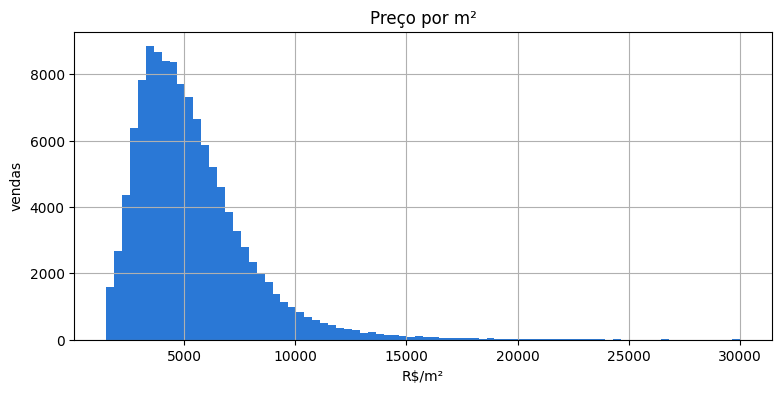

In [6]:
ax = d['preco_m2'].clip(upper=30_000).hist(bins=80, color='#2a78d6')
ax.set(title='Preço por m²', xlabel='R$/m²', ylabel='vendas');

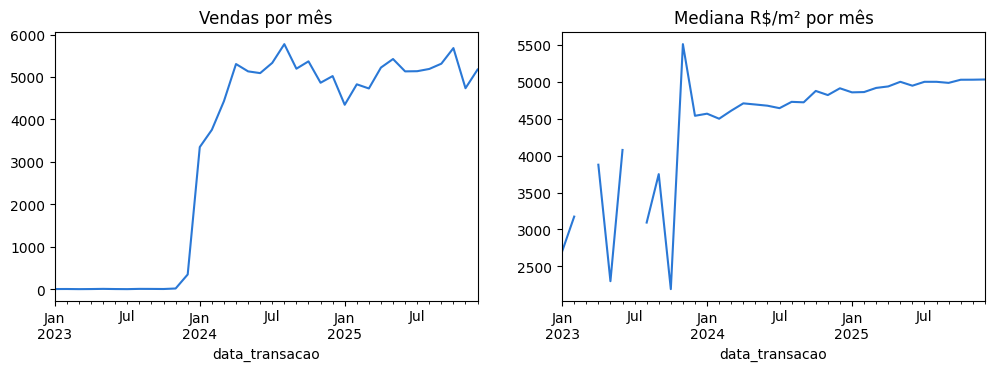

In [7]:
vol = d.set_index('data_transacao').resample('MS')['preco_m2'].agg(['size', 'median'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
vol['size'].plot(ax=ax[0], color='#2a78d6', title='Vendas por mês')
vol['median'].plot(ax=ax[1], color='#2a78d6', title='Mediana R$/m² por mês');

Volume cai nos últimos meses porque a guia é paga depois da escritura: venda de dezembro ainda vai aparecer nos arquivos de 2026. Por isso o teste usa o 2º semestre de 2025 inteiro e não só o fim do ano.

## Padrão construtivo do IPTU

In [8]:
d['classe'] = (d['padrao_cod'] % 10).map(dict(zip(range(1, 7), 'ABCDEF')))
d.groupby('classe')['preco_m2'].agg(['size', 'median'])

,size,median
classe,,
A,8544,"3,684.21"
B,87822,"4,727.27"
C,18806,"6,149.34"
D,3316,"7,101.00"
E,148,"11,444.00"


Cresce de A a E (não aparece F nos apartamentos vendidos), como esperado. Vai como numérica mesmo.

## Localização

Não tem coordenada, só CEP. Os 3 primeiros dígitos já separam bem as regiões:

In [9]:
cep3 = d.groupby(d['cep'].str[:3])['preco_m2'].agg(['size', 'median'])
cep3 = cep3[cep3['size'] >= 200].sort_values('median')
pd.concat([cep3.head(5), cep3.tail(5)])

,size,median
cep,,
084,737,"2,109.37"
083,356,"2,829.08"
080,523,"2,990.65"
058,1021,"3,009.71"
038,402,"3,071.73"
047,4377,"6,233.79"
040,5616,"6,779.66"
054,4546,"7,624.11"
045,6455,"8,281.20"


In [10]:
print('CEPs de 5 dígitos:', d['cep'].str[:5].nunique())
print('mediana de vendas por CEP5:', d.groupby(d['cep'].str[:5]).size().median())

CEPs de 5 dígitos: 2253


mediana de vendas por CEP5: 31.0


Milhares de categorias com poucas vendas cada → target encoding com validação cruzada em vez de one-hot.

## Valor venal x preço declarado

In [11]:
r = d['valor_transacao'] / d['valor_venal_ref']
r.describe(percentiles=[.1, .5, .9])

count   119,912.00
mean          1.38
std           0.48
min           0.30
10%           0.88
50%           1.30
90%           1.96
max           4.99
dtype: float64

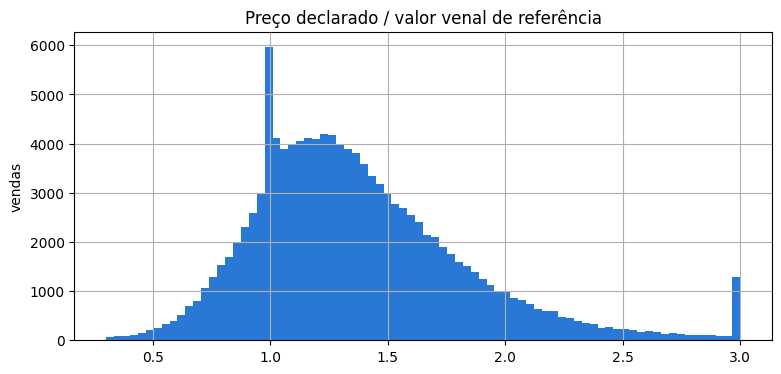

In [12]:
ax = r.clip(upper=3).hist(bins=80, color='#2a78d6')
ax.set(title='Preço declarado / valor venal de referência', ylabel='vendas');

In [13]:
np.corrcoef(np.log(d['valor_transacao']), np.log(d['valor_venal_ref']))[0, 1]

np.float64(0.8973682418175253)

Em geral o preço declarado fica uns 30% acima do venal de referência, mas a correlação no log é de ~0,90: o venal acompanha bem a ordem de grandeza. Dá pra usar como feature porque ele é conhecido antes da venda, mas treino um modelo com e outro sem para ver quanto do resultado vem dele.